# 00 - Data Exploration, Cleaning & Regional Preparation
### Day-ahead forecasting of French electricity demand - the data layer

This notebook is the **single source of clean data** for the whole project. It loads the raw files, validates and
cleans them, prepares the 12 regional series, checks that the regions reconcile to the national total, compares
how each region varies around the national demand pattern, and saves tidy cleaned datasets that
**Notebook 01 (analysis)** and **Notebooks 02-03 (modelling)** load directly.

**Two datasets**
- `france_electricity_hourly.csv` - **national**, hourly UTC **2019-01 -> 2026-06**, with columns
  `load_mw` (target), `rte_forecast_d1_mw` (RTE benchmark) and `temperature_c`.
- `france_regional_electricity_hourly.csv.gz` - the **12 metropolitan regions**, hourly UTC **2023-01 -> 2026-06**,
  with `load_mw` and a region-specific `temperature_c` (no per-region RTE forecast).

**What this notebook delivers**
1. Structural validation of both series (continuity, duplicates, missing values).
2. Honest cleaning of the few missing values, with the *reason* they are missing.
3. Regional preparation + a **reconciliation check** (do the 12 regions sum to the national total?).
4. The **national mean recomputed over the common 2023-2026 window**, for fair regional comparison.
5. Visuals comparing **each region's demand variation against the national pattern**.
6. Cleaned datasets saved to `data/processed/` for every downstream notebook.

## 0 - Setup
Libraries and one colourblind-safe visual style, shared with the other notebooks.

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import LinearSegmentedColormap
import holidays as holidays_lib

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("Ready - pandas", pd.__version__, "| numpy", np.__version__)

Ready - pandas 3.0.6 | numpy 2.5.2


In [2]:
# ---- Shared visual system (brand-neutral, validated, colourblind-safe) ----
PALETTE = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
    "violet": "#6250d6", "red": "#e34948", "green": "#0ca30c",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "surface": "#fcfcfb",
}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
BLUE_CMAP = LinearSegmentedColormap.from_list("brand_blue", BLUE_RAMP)
DIVERGING = LinearSegmentedColormap.from_list(
    "brand_div", ["#184f95", "#86b6ef", "#f0efec", "#eb8f8f", "#c0201f"])

plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "savefig.bbox": "tight",
    "axes.edgecolor": PALETTE["muted"], "axes.linewidth": 0.8,
    "axes.labelcolor": PALETTE["ink2"], "axes.titlecolor": PALETTE["ink"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 10, "axes.labelsize": 11,
    "text.color": PALETTE["ink"], "xtick.color": PALETTE["muted"], "ytick.color": PALETTE["muted"],
    "xtick.labelcolor": PALETTE["ink2"], "ytick.labelcolor": PALETTE["ink2"],
    "axes.grid": True, "grid.color": PALETTE["grid"], "grid.linewidth": 0.8, "grid.alpha": 0.9,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "legend.frameon": False, "legend.fontsize": 10,
    "figure.dpi": 110, "figure.titlesize": 14, "figure.titleweight": "bold", "lines.linewidth": 1.8,
})
gw_fmt  = FuncFormatter(lambda v, _: f"{v/1000:,.0f}")
gw1_fmt = FuncFormatter(lambda v, _: f"{v/1000:,.1f}")

def titled(ax, title=None, xlabel=None, ylabel=None):
    if title is not None: ax.set_title(title, loc="left")
    if xlabel is not None: ax.set_xlabel(xlabel)
    if ylabel is not None: ax.set_ylabel(ylabel)
    ax.margins(x=0.01)
    return ax

SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
FIG = Path("..") / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
print("Visual style loaded.")

Visual style loaded.


## 1 - Load the raw data
National (2019-2026) and regional (2023-2026, 12 regions in long format).

In [3]:
NAT = Path("..") / "data" / "france_electricity_hourly.csv"
REG = Path("..") / "data" / "france_regional_electricity_hourly.csv.gz"

nat_raw = (pd.read_csv(NAT, parse_dates=["datetime_utc"]).set_index("datetime_utc").sort_index())
reg_raw = pd.read_csv(REG, parse_dates=["datetime_utc"])

regions = sorted(reg_raw["region"].unique())
print(f"NATIONAL : {len(nat_raw):,} rows | {nat_raw.index.min()} -> {nat_raw.index.max()}")
print(f"REGIONAL : {len(reg_raw):,} rows | {reg_raw['datetime_utc'].min()} -> {reg_raw['datetime_utc'].max()}")
print(f"           {len(regions)} regions: {regions}")
reg_raw.head()

NATIONAL : 65,712 rows | 2019-01-01 00:00:00+00:00 -> 2026-06-30 23:00:00+00:00
REGIONAL : 367,752 rows | 2023-01-01 00:00:00+00:00 -> 2026-06-30 21:00:00+00:00
           12 regions: ['Auvergne-Rhône-Alpes', 'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire', 'Grand Est', 'Hauts-de-France', 'Normandie', 'Nouvelle-Aquitaine', 'Occitanie', 'Pays de la Loire', "Provence-Alpes-Côte d'Azur", 'Île-de-France']


,region,datetime_utc,load_mw,temperature_c
0,Auvergne-Rhône-Alpes,2023-01-01 00:00:00+00:00,"6,028.000",13.300
1,Auvergne-Rhône-Alpes,2023-01-01 01:00:00+00:00,"6,165.000",13.200
2,Auvergne-Rhône-Alpes,2023-01-01 02:00:00+00:00,"6,282.000",13.000
3,Auvergne-Rhône-Alpes,2023-01-01 03:00:00+00:00,"5,779.000",12.800
4,Auvergne-Rhône-Alpes,2023-01-01 04:00:00+00:00,"5,526.000",12.700


## 2 - Structural validation
Is each series a continuous, duplicate-free hourly grid? The regional panel must also be *balanced* (same hours for every region).

In [4]:
# National grid
nat_full = pd.date_range(nat_raw.index.min(), nat_raw.index.max(), freq="h", tz="UTC")
nat_checks = {
    "expected hourly rows": f"{len(nat_full):,}", "actual rows": f"{len(nat_raw):,}",
    "missing hours": f"{len(nat_full.difference(nat_raw.index)):,}",
    "duplicate timestamps": f"{int(nat_raw.index.duplicated().sum()):,}",
}

# Regional grid (balanced panel?)
counts = reg_raw["region"].value_counts()
uniq_ts = pd.DatetimeIndex(reg_raw["datetime_utc"].unique()).sort_values()
reg_full = pd.date_range(uniq_ts.min(), uniq_ts.max(), freq="h", tz="UTC")
reg_checks = {
    "regions": f"{reg_raw['region'].nunique()}", "rows per region (balanced?)": f"{counts.min():,}-{counts.max():,}",
    "unique timestamps": f"{len(uniq_ts):,}", "missing hours in grid": f"{len(reg_full.difference(uniq_ts)):,}",
    "duplicate (region,time)": f"{int(reg_raw.duplicated(['region','datetime_utc']).sum()):,}",
}
print("NATIONAL:"); [print(f"  {k:28s}: {v}") for k, v in nat_checks.items()]
print("REGIONAL:"); [print(f"  {k:28s}: {v}") for k, v in reg_checks.items()]

NATIONAL:
  expected hourly rows        : 65,712
  actual rows                 : 65,712
  missing hours               : 0
  duplicate timestamps        : 0
REGIONAL:
  regions                     : 12
  rows per region (balanced?) : 30,646-30,646
  unique timestamps           : 30,646
  missing hours in grid       : 0
  duplicate (region,time)     : 0


[None, None, None, None, None]

Both grids are clean: the national series is continuous, and the regional file is a **balanced panel** -
every region has the same 30,646 hours on one shared, gap-free grid. The only issue is a handful of missing
*values*, isolated next.

## 3 - Missing values & the DST artifact
The same explainable cause in both files: the autumn daylight-saving change.

In [5]:
nat_na = nat_raw[nat_raw.isna().any(axis=1)]
reg_na = reg_raw[reg_raw["load_mw"].isna()]
print(f"NATIONAL missing values : {len(nat_na)}  on dates {[str(d) for d in sorted(set(nat_na.index.date))]}")
print(f"REGIONAL missing values : {len(reg_na)}  (= {reg_na['region'].nunique()} regions x "
      f"{reg_na['datetime_utc'].dt.date.nunique()} dates)")
print(f"REGIONAL missing dates  : {sorted(set(reg_na['datetime_utc'].dt.date.astype(str)))}")

# confirm every missing timestamp is the last Sunday of October (autumn DST 'fall-back')
def last_sundays_oct(y0, y1):
    out = []
    for y in range(y0, y1 + 1):
        d = pd.Timestamp(year=y, month=10, day=31)
        while d.weekday() != 6:
            d -= pd.Timedelta(days=1)
        out.append(d.date())
    return set(out)

dst = last_sundays_oct(2019, 2026)
nat_ok = set(nat_na.index.date).issubset(dst)
reg_ok = set(reg_na["datetime_utc"].dt.date).issubset(dst)
print(f"\nAll national gaps on the autumn DST change: {nat_ok}")
print(f"All regional gaps on the autumn DST change: {reg_ok}")

NATIONAL missing values : 7  on dates ['2019-10-27', '2020-10-25', '2021-10-31', '2022-10-30', '2023-10-29', '2024-10-27', '2025-10-26']
REGIONAL missing values : 36  (= 12 regions x 3 dates)
REGIONAL missing dates  : ['2023-10-29', '2024-10-27', '2025-10-26']

All national gaps on the autumn DST change: True
All regional gaps on the autumn DST change: True


In [6]:
# ---- Clean NATIONAL: formalise the grid, impute the 7 DST gaps by time interpolation ----
nat = nat_raw.reindex(nat_full).copy()
nat.index.name = "datetime_utc"
nat[["load_mw", "rte_forecast_d1_mw"]] = (
    nat[["load_mw", "rte_forecast_d1_mw"]].interpolate(method="time", limit_direction="both"))

# ---- Clean REGIONAL: pivot to wide (time x region), then interpolate each region in time ----
reg_load = reg_raw.pivot(index="datetime_utc", columns="region", values="load_mw").sort_index().reindex(reg_full)
reg_temp = reg_raw.pivot(index="datetime_utc", columns="region", values="temperature_c").sort_index().reindex(reg_full)
na_before = int(reg_load.isna().sum().sum())
reg_load = reg_load.interpolate(method="time", limit_direction="both")
reg_temp = reg_temp.interpolate(method="time", limit_direction="both")

print("NATIONAL missing after cleaning :", nat[["load_mw", "rte_forecast_d1_mw"]].isna().sum().to_dict())
print(f"REGIONAL load missing: {na_before} before  ->  {int(reg_load.isna().sum().sum())} after")
print("Regional wide load matrix:", reg_load.shape, "(hours x regions)")

NATIONAL missing after cleaning : {'load_mw': 0, 'rte_forecast_d1_mw': 0}
REGIONAL load missing: 36 before  ->  0 after
Regional wide load matrix: (30646, 12) (hours x regions)


## 4 - Calendar enrichment (Paris local time)
Seasonality follows the local clock, so we derive hour / weekday / month / season / holiday flags in Europe/Paris.

In [7]:
local = nat.index.tz_convert("Europe/Paris")
nat["hour"] = local.hour; nat["dow"] = local.dayofweek; nat["month"] = local.month
nat["year"] = local.year; nat["is_weekend"] = nat["dow"] >= 5; nat["season"] = nat["month"].map(SEASON)
fr_hol = holidays_lib.France(years=range(nat["year"].min(), nat["year"].max() + 1))
nat["is_holiday"] = pd.Series([d in fr_hol for d in local.date], index=nat.index)
print("National calendar features added. Public-holiday hours:", int(nat["is_holiday"].sum()))

# Lightweight time index for regional profiles (shared across regions)
reg_local = reg_load.index.tz_convert("Europe/Paris")
reg_hour  = pd.Series(reg_local.hour,  index=reg_load.index)
reg_month = pd.Series(reg_local.month, index=reg_load.index)
print("Regional time index ready.")

National calendar features added. Public-holiday hours: 1991
Regional time index ready.


## 5 - Regional preparation & reconciliation
A hierarchy is only valid if the parts sum to the whole. We check that the 12 regions reconcile to the national
total over their common period - this is what licenses the bottom-up / hierarchical approach in Notebook 03.

In [8]:
reg_sum = reg_load.sum(axis=1)
overlap = reg_sum.index.intersection(nat.index)        # the common 2023-2026 window
recon = pd.DataFrame({"national": nat.loc[overlap, "load_mw"], "regional_sum": reg_sum.loc[overlap]})
recon["diff"] = recon["regional_sum"] - recon["national"]

print(f"Common period : {overlap.min()} -> {overlap.max()}  ({len(overlap):,} hours)")
print(f"Mean national      : {recon['national'].mean():,.0f} MW")
print(f"Mean regional sum  : {recon['regional_sum'].mean():,.0f} MW")
print(f"Ratio reg/nat      : {recon['regional_sum'].mean()/recon['national'].mean():.4f}")
print(f"Mean |difference|  : {recon['diff'].abs().mean():,.0f} MW  "
      f"({recon['diff'].abs().mean()/recon['national'].mean()*100:.3f}% of load)")

Common period : 2023-01-01 00:00:00+00:00 -> 2026-06-30 21:00:00+00:00  (30,646 hours)
Mean national      : 50,526 MW
Mean regional sum  : 50,517 MW
Ratio reg/nat      : 0.9998
Mean |difference|  : 16 MW  (0.032% of load)


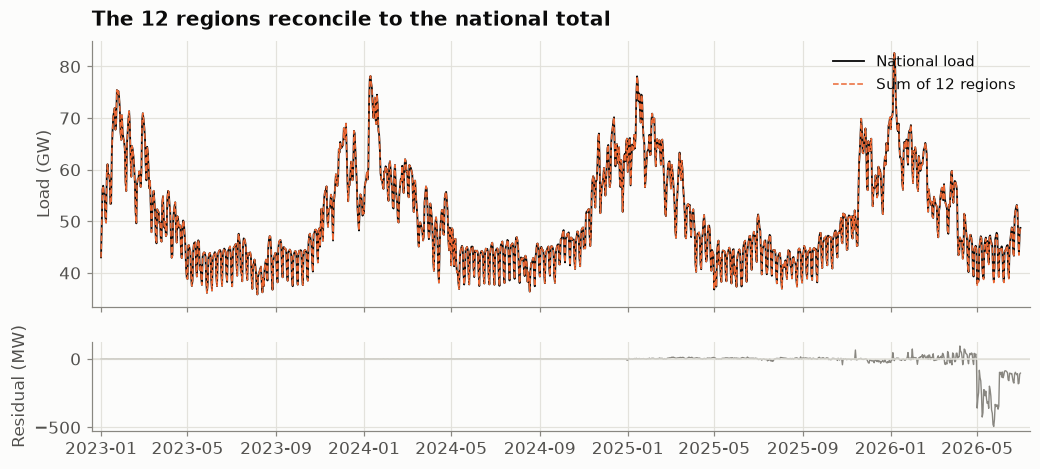

In [9]:
# Visual: the two curves are indistinguishable; the residual is tiny.
rec_d = recon.resample("D").mean()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 4.6), height_ratios=[3, 1], sharex=True)
a1.plot(rec_d.index, rec_d["national"], color=PALETTE["ink"], lw=1.2, label="National load")
a1.plot(rec_d.index, rec_d["regional_sum"], color=PALETTE["orange"], lw=1.0, ls="--", label="Sum of 12 regions")
a1.yaxis.set_major_formatter(gw_fmt); a1.legend(loc="upper right")
titled(a1, "The 12 regions reconcile to the national total", ylabel="Load (GW)")
a2.plot(rec_d.index, rec_d["diff"], color=PALETTE["muted"], lw=0.9)
a2.axhline(0, color=PALETTE["grid"], lw=1)
titled(a2, None, xlabel="", ylabel="Residual (MW)")
fig.savefig(FIG / "00_reconciliation.png")
plt.show()

## 6 - Recompute the mean over the common period
The national file spans 2019-2026, but the regions only exist from 2023. To compare them fairly we recompute the
**national mean on the common 2023-2026 window** and summarise each region over the same window.

In [10]:
nat_mean_full    = nat_raw["load_mw"].mean()
nat_mean_overlap = nat.loc[overlap, "load_mw"].mean()
print(f"National mean, FULL history (2019-2026)   : {nat_mean_full:,.0f} MW")
print(f"National mean, COMMON window (2023-2026)   : {nat_mean_overlap:,.0f} MW")
print(f"Difference from using the full history     : {nat_mean_full - nat_mean_overlap:+,.0f} MW "
      f"({(nat_mean_full/nat_mean_overlap-1)*100:+.1f}%)\n")

reg_mean = reg_load.loc[overlap].mean().sort_values(ascending=False)
summary = pd.DataFrame({
    "mean_load_mw": reg_mean.round(0),
    "share_pct": (reg_mean / reg_mean.sum() * 100).round(1),
    "mean_temp_c": reg_temp.loc[overlap].mean().reindex(reg_mean.index).round(1),
})
summary.loc["NATIONAL (sum)"] = [reg_mean.sum().round(0), 100.0, np.nan]
summary

National mean, FULL history (2019-2026)   : 51,503 MW
National mean, COMMON window (2023-2026)   : 50,526 MW
Difference from using the full history     : +977 MW (+1.9%)



,mean_load_mw,share_pct,mean_temp_c
region,,,
Île-de-France,"7,426.000",14.700,12.700
Auvergne-Rhône-Alpes,"7,111.000",14.100,13.100
Hauts-de-France,"5,331.000",10.600,11.800
Grand Est,"4,771.000",9.400,12.000
Nouvelle-Aquitaine,"4,706.000",9.300,14.500
Provence-Alpes-Côte d'Azur,"4,406.000",8.700,15.900
Occitanie,"4,153.000",8.200,14.500
Normandie,"2,963.000",5.900,11.800
Pays de la Loire,"2,900.000",5.700,13.400


## 7 - How each region varies against the national pattern
Regions differ in **size**, **climate** and **shape**. Below we compare them to the national demand profile. Because
12 series are too many to overlay legibly, we use **small multiples** (one panel per region) with the national
profile as a grey reference, and index every series to its own mean (= 100) so *shape* is compared, not size.

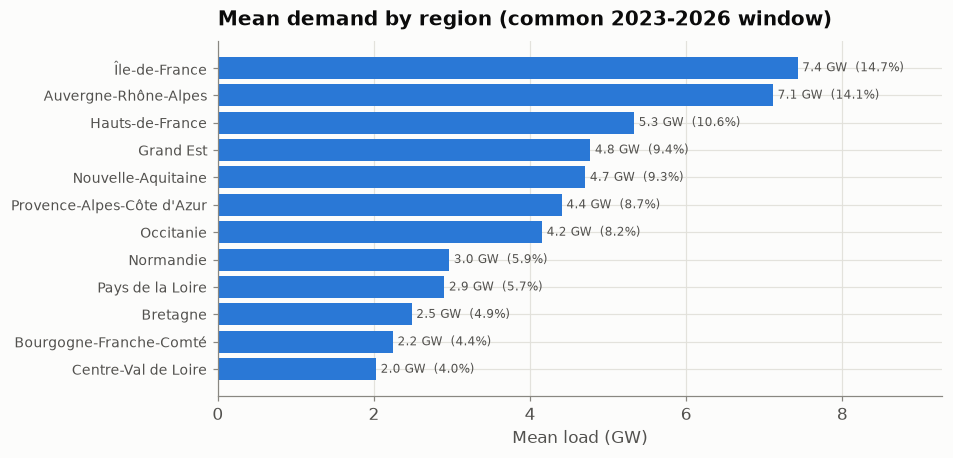

In [11]:
# 7a - Size: mean load and share of national (common window)
m = reg_load.loc[overlap].mean().sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(m)), m.values, color=PALETTE["blue"])
ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index, fontsize=9)
for i, v in enumerate(m.values):
    ax.text(v + 60, i, f"{v/1000:,.1f} GW  ({v/m.sum()*100:.1f}%)", va="center", fontsize=8, color=PALETTE["ink2"])
ax.xaxis.set_major_formatter(gw_fmt); ax.set_xlim(0, m.max() * 1.25)
titled(ax, "Mean demand by region (common 2023-2026 window)", xlabel="Mean load (GW)")
fig.savefig(FIG / "00_region_size.png")
plt.show()

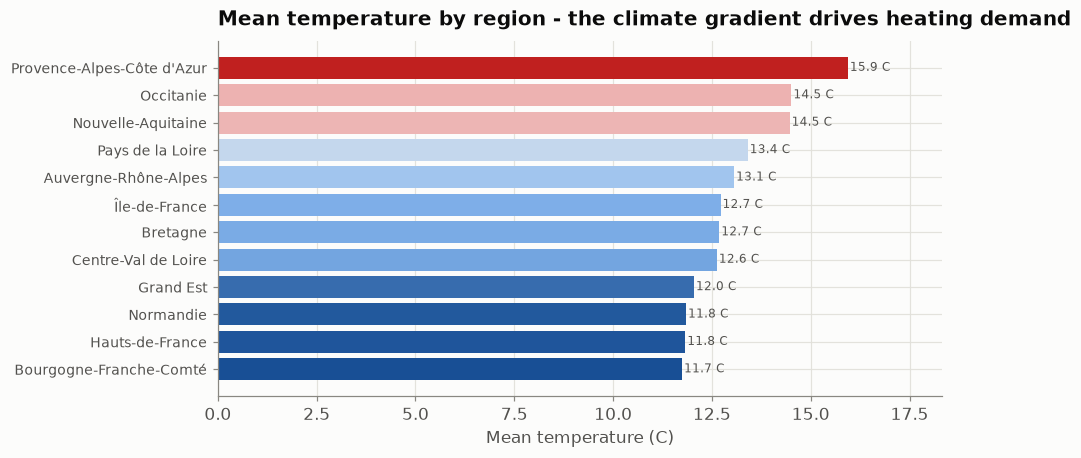

In [12]:
# 7b - Climate: mean temperature by region (the north-cold / south-warm gradient)
t = reg_temp.loc[overlap].mean().sort_values()
norm = (t.values - t.values.min()) / (t.values.max() - t.values.min())
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(t)), t.values, color=DIVERGING(norm))
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=9)
for i, v in enumerate(t.values):
    ax.text(v + 0.05, i, f"{v:.1f} C", va="center", fontsize=8, color=PALETTE["ink2"])
ax.set_xlim(0, t.max() * 1.15)
titled(ax, "Mean temperature by region - the climate gradient drives heating demand", xlabel="Mean temperature (C)")
fig.savefig(FIG / "00_region_climate.png")
plt.show()

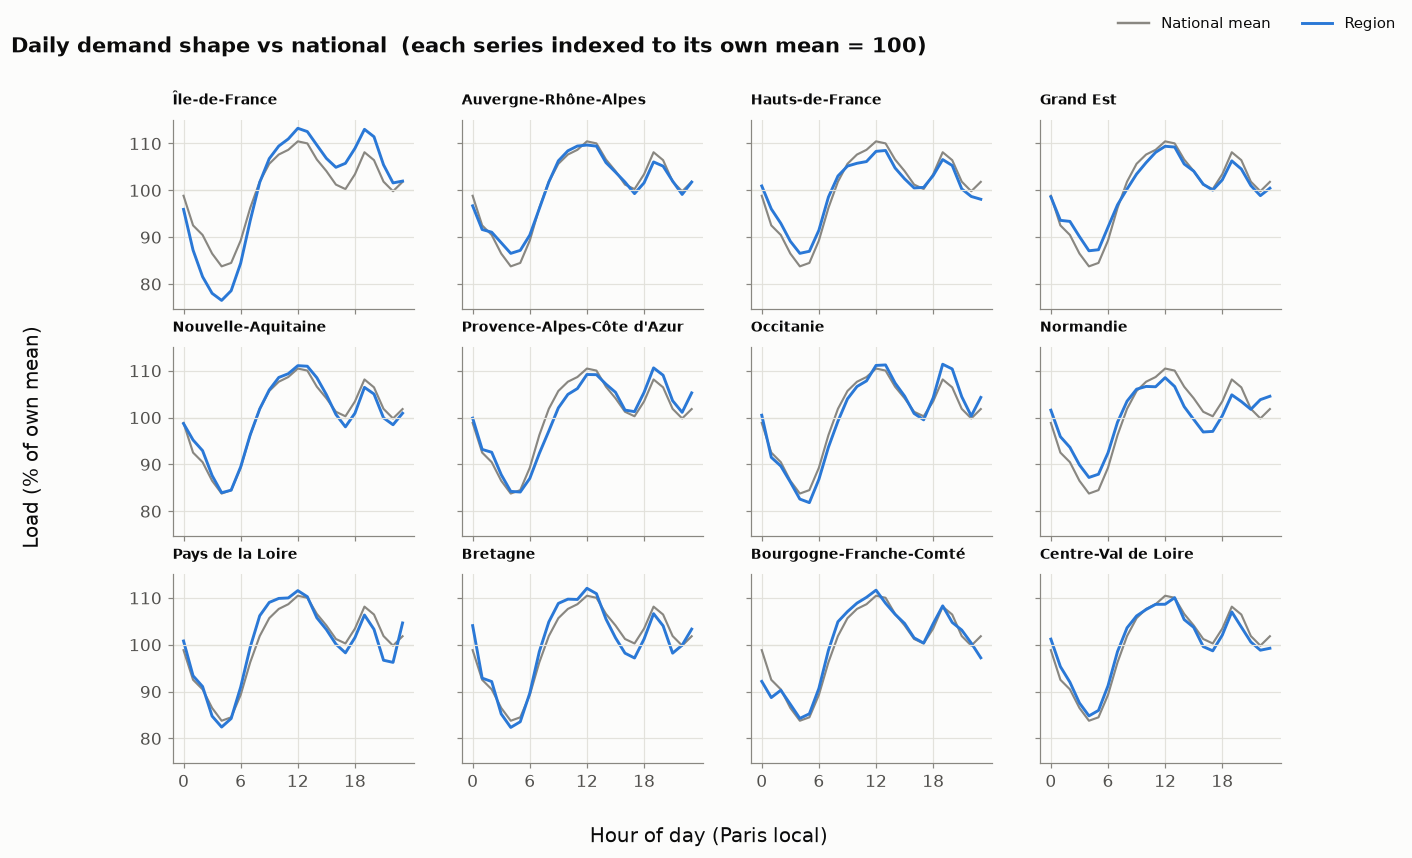

In [13]:
# 7c - Shape vs national: normalised average DAILY profile (index to own mean = 100), small multiples
nat_ov = nat.loc[overlap, "load_mw"]
nat_daily = nat_ov.groupby(reg_hour.values).mean()
nat_daily_idx = nat_daily / nat_daily.mean() * 100

order = reg_load.loc[overlap].mean().sort_values(ascending=False).index   # biggest first
fig, axes = plt.subplots(3, 4, figsize=(13, 7.6), sharex=True, sharey=True)
for ax, rg in zip(axes.flat, order):
    prof = reg_load.loc[overlap, rg].groupby(reg_hour.values).mean()
    idx = prof / prof.mean() * 100
    ax.plot(nat_daily_idx.index, nat_daily_idx.values, color=PALETTE["muted"], lw=1.4, label="National")
    ax.plot(idx.index, idx.values, color=PALETTE["blue"], lw=1.9, label="Region")
    ax.axhline(100, color=PALETTE["grid"], lw=0.8)
    ax.set_title(rg, fontsize=9, loc="left")
    ax.set_xticks(range(0, 24, 6))
handles = [plt.Line2D([], [], color=PALETTE["muted"], lw=1.6, label="National mean"),
           plt.Line2D([], [], color=PALETTE["blue"], lw=1.9, label="Region")]
fig.legend(handles=handles, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Daily demand shape vs national  (each series indexed to its own mean = 100)", x=0.012, ha="left")
fig.supxlabel("Hour of day (Paris local)"); fig.supylabel("Load (% of own mean)")
fig.savefig(FIG / "00_region_daily_shape.png")
plt.show()

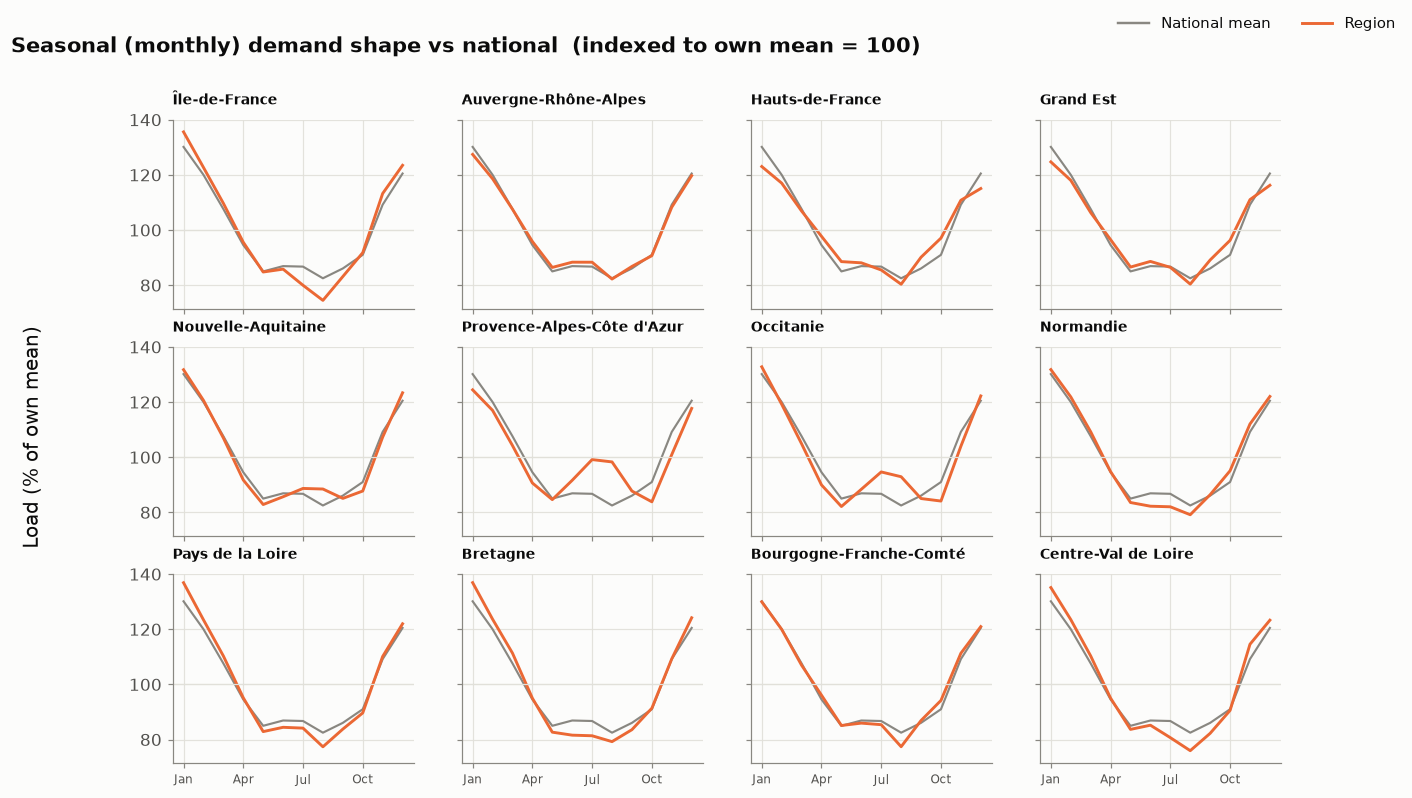

In [14]:
# 7d - Shape vs national: normalised MONTHLY profile (seasonality strength), small multiples
nat_month = nat_ov.groupby(reg_month.values).mean()
nat_month_idx = nat_month / nat_month.mean() * 100

fig, axes = plt.subplots(3, 4, figsize=(13, 7.6), sharex=True, sharey=True)
for ax, rg in zip(axes.flat, order):
    prof = reg_load.loc[overlap, rg].groupby(reg_month.values).mean()
    idx = prof / prof.mean() * 100
    ax.plot(nat_month_idx.index, nat_month_idx.values, color=PALETTE["muted"], lw=1.4)
    ax.plot(idx.index, idx.values, color=PALETTE["orange"], lw=1.9)
    ax.axhline(100, color=PALETTE["grid"], lw=0.8)
    ax.set_title(rg, fontsize=9, loc="left"); ax.set_xticks([1, 4, 7, 10])
    ax.set_xticklabels(["Jan", "Apr", "Jul", "Oct"], fontsize=8)
handles = [plt.Line2D([], [], color=PALETTE["muted"], lw=1.6, label="National mean"),
           plt.Line2D([], [], color=PALETTE["orange"], lw=1.9, label="Region")]
fig.legend(handles=handles, loc="upper right", ncol=2, bbox_to_anchor=(0.99, 1.02))
fig.suptitle("Seasonal (monthly) demand shape vs national  (indexed to own mean = 100)", x=0.012, ha="left")
fig.supylabel("Load (% of own mean)")
fig.savefig(FIG / "00_region_monthly_shape.png")
plt.show()

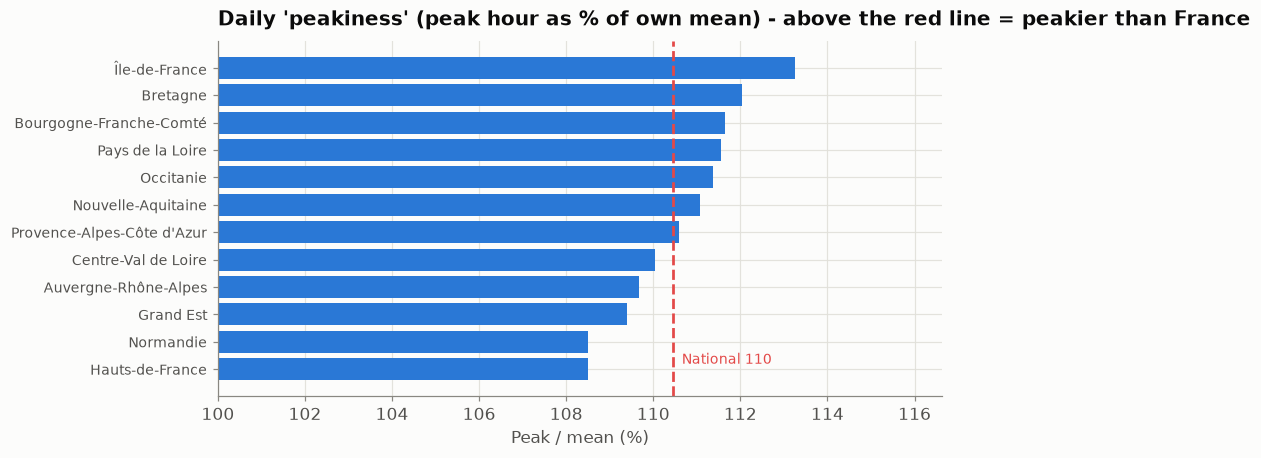

In [15]:
# 7e - Variability summary: how 'peaky' is each region vs the nation?
peak_mean = {}
for rg in order:
    prof = reg_load.loc[overlap, rg].groupby(reg_hour.values).mean()
    peak_mean[rg] = prof.max() / prof.mean() * 100
pm = pd.Series(peak_mean).sort_values()
nat_pm = nat_daily.max() / nat_daily.mean() * 100

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.barh(range(len(pm)), pm.values, color=PALETTE["blue"])
ax.axvline(nat_pm, color=PALETTE["red"], lw=1.8, ls="--")
ax.text(nat_pm + 0.2, 0.2, f"National {nat_pm:.0f}", color=PALETTE["red"], fontsize=9)
ax.set_yticks(range(len(pm))); ax.set_yticklabels(pm.index, fontsize=9)
ax.set_xlim(100, pm.max() * 1.03)
titled(ax, "Daily 'peakiness' (peak hour as % of own mean) - above the red line = peakier than France",
       xlabel="Peak / mean (%)")
fig.savefig(FIG / "00_region_peakiness.png")
plt.show()

**What the comparison shows.** Regions share France's core rhythm (morning ramp, winter-evening peak) but
differ in two ways that matter for forecasting: (i) **climate** - cold northern/continental regions have the
steepest winter seasonality, while the Mediterranean south is flatter and shows the only real summer-cooling bump;
(ii) **peakiness** - some regions swing more sharply around their mean than the nation does. Those differences are
exactly why a **bottom-up regional model with each region's own temperature** could sharpen the national forecast -
the hypothesis Notebook 03 will test.

## 8 - Define the split and save the cleaned datasets
A fixed chronological split (used by every later notebook) is attached to the national data, then everything is
written to `data/processed/` as CSV.

In [16]:
# chronological split on the national series
nat["split"] = np.select([nat["year"] <= 2023, nat["year"] == 2024], ["train", "val"], default="test")

proc = Path("..") / "data" / "processed"
proc.mkdir(parents=True, exist_ok=True)

# (a) cleaned national, calendar features + split
keep_nat = ["load_mw", "rte_forecast_d1_mw", "temperature_c",
            "hour", "dow", "month", "year", "is_weekend", "is_holiday", "season", "split"]
nat[keep_nat].to_csv(proc / "france_clean_hourly.csv", index_label="datetime_utc")

# (b) cleaned regional in tidy long format (load + temperature + light calendar)
load_long = reg_load.reset_index(names="datetime_utc").melt("datetime_utc", var_name="region", value_name="load_mw")
temp_long = reg_temp.reset_index(names="datetime_utc").melt("datetime_utc", var_name="region", value_name="temperature_c")
reg_long = load_long.merge(temp_long, on=["datetime_utc", "region"])
rl = reg_long["datetime_utc"].dt.tz_convert("Europe/Paris")
reg_long["hour"] = rl.dt.hour; reg_long["month"] = rl.dt.month; reg_long["season"] = reg_long["month"].map(SEASON)
reg_long.to_csv(proc / "france_regional_clean_hourly.csv", index=False)

# (c) the regional summary over the common window
summary.to_csv(proc / "regional_overlap_summary.csv")

print("Saved to data/processed/:")
print(f"  france_clean_hourly.csv          {nat[keep_nat].shape}  (national, 2019-2026)")
print(f"  france_regional_clean_hourly.csv {reg_long.shape}  (regional long, 2023-2026)")
print(f"  regional_overlap_summary.csv         {summary.shape}")

Saved to data/processed/:
  france_clean_hourly.csv          (65712, 11)  (national, 2019-2026)
  france_regional_clean_hourly.csv (367752, 7)  (regional long, 2023-2026)
  regional_overlap_summary.csv         (13, 3)


## 9 - Summary

**Data quality - excellent in both files.**
- National: continuous hourly grid 2019-2026, no duplicates; **7 missing values** (autumn DST) imputed.
- Regional: **balanced panel** of 12 regions 2023-2026, no duplicates; **36 missing values** (3 DST dates x 12 regions) imputed.

**The hierarchy is valid.**
- The 12 regions **reconcile to the national total** to within **~16 MW (0.03%)** - bottom-up forecasting is legitimate.

**Fair comparison basis.**
- National mean recomputed on the common window: **~50.5 GW** (vs ~51.5 GW on the full 2019-2026 history).
- Ile-de-France and Auvergne-Rhone-Alpes are the largest (~14% each); a clear north-cold / south-warm climate gradient.
- Regions share the national rhythm but differ in seasonality strength and peakiness - motivation for regional modelling.

**Saved for downstream notebooks**
- `france_clean_hourly.csv` (national + calendar + split) -> **Notebook 01 (analysis)** and 02-03 (modelling).
- `france_regional_clean_hourly.csv` (regional long) + `regional_overlap_summary.csv` -> the hierarchical bonus in Notebook 03.

**Next - Notebook 01:** deep exploratory analysis on the cleaned national series (seasonality, stationarity tests,
temperature response, and the RTE benchmark audit).